The problem is that I should use proper barcode counting, I must see how many of barcodes I am counting from barcode sequencing
Some of those barcodes have N in their sequence and with simple matching you can't use them, there should be proper way to assign them, like minimap2

In [1]:
import itertools
import os
import re
import warnings

import sfmap_normal
from scipy.stats import pearsonr, mannwhitneyu, wilcoxon, gaussian_kde, ttest_ind

import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 300  # High resolution
import numpy as np

from datetime import datetime
from collections import Counter

from matplotlib_venn import venn3, venn3_circles


import alignparse.targets
import seaborn as sns
from IPython.display import display, HTML
from matplotlib.backends.backend_pdf import PdfPages


from sklearn.decomposition import PCA
from adjustText import adjust_text

import pandas as pd
from pathlib import Path
from sklearn.metrics import r2_score

from Bio.Seq import Seq
from Bio import SeqIO

import random

import matplotlib as mpl
mpl.rcParams['font.family'] = 'Helvetica'

# Set global font to Helvetica
mpl.rcParams['font.family'] = 'Helvetica'


import yaml
warnings.simplefilter('ignore')

In [2]:
plot_cmap = {
    
    "EmberRed": "#7C1900",
    "TranqMist": "#466058",
    "SapphBlue": "#438CBD",
    "GoldHarmon": "#DACF6D",
    "AmberBurst": "#9E5817",
    "AzureDream": "#61BDD2",
    "CopperSet": "#B99131",
    "TwilightIndigo": "#305CAB",
    "green": "#278343",
    "grey" : "#b7b7b7"
}

Read the configuration file:

In [3]:
with open('config.yaml') as f:
    config = yaml.safe_load(f)

Make output directory for counts:

## Load Codon-Variant table

In [4]:
#read codon_variant_table generated by pacbio sequencing and pbData_analysis
variants = pd.read_table(f'{config["codon_variant_table_file"]}', na_filter=None, sep=',')


        
display(HTML(variants.head().to_html(index=False)))

library,barcode,variant_call_support,number_of_indels,codon_substitutions,aa_substitutions,n_codon_substitutions,n_aa_substitutions,variant_class,aa_substitutions_c
GBA1,AAGCGGACTGCACGTCGTCTTTTTTTTTTT,1,0,,,0,0,wildtype,wildtype
GBA1,ACCATGTATCGACCCTATCATTTTTTTTTT,1,0,CGC78CAG,R78Q,1,1,1 nonsynonymous,R78Q
GBA1,TAAGTCGCTGCGCGGATGTCGTTTTTTTTT,13,0,,,0,0,wildtype,wildtype
GBA1,AGGCAAAACTGCTACTTGCCTGTTTTTTTT,8,0,AGC47TGG,S47W,1,1,1 nonsynonymous,S47W
GBA1,TTGTTTAGCTGTCAACCCCCCGTTTTTTTT,44,0,,,0,0,wildtype,wildtype


Read the PacBio amplicon target sequence and translate it to protein

In [5]:
plot_cmap = {
    
    "EmberRed": "#7C1900",
    "TranqMist": "#466058",
    "SapphBlue": "#438CBD",
    "GoldHarmon": "#DACF6D",
    "AmberBurst": "#9E5817",
    "AzureDream": "#61BDD2",
    "CopperSet": "#B99131",
    "TwilightIndigo": "#305CAB",
    "green": "#278343",
    "grey" : "#b7b7b7"
}




name_map = {
    'gba1_r1': 'gba1_r1 Gcase flowSeq',
}



Classify the variants and flag wt and synonymous variants in aa_substitutions column

In [6]:
#can assign variatn class column if not present in df generated by pbData_analysis.ipynb
def classify_variants(df):
    def classify(row):
        if row["n_codon_substitutions"] == 0:
            return "wildtype"
        elif row["n_codon_substitutions"] > 0 and row["n_aa_substitutions"] == 0:
            return "synonymous"
        elif "*" in str(row["aa_substitutions"]) and row["n_aa_substitutions"]==1:
            return "stop"
        elif row["n_aa_substitutions"] == 1:
            return "1 nonsynonymous"
        else:
            return ">1 nonsynonymous"
    df["variant_class"] = df.apply(classify, axis=1)
    return df


variants=classify_variants(variants)
variants['aa_substitutions']=variants['aa_substitutions'].where(variants['aa_substitutions'] != '', variants['variant_class'])

## Read enrich2 barcode counts (values) for each facs run (key) as dict
We want to see how many of the barcodes per single variant (assigned by PacBio) have got reads after in FACS sorting

In [7]:
col_names = ['barcode','bin1', 'bin2', 'bin3', 'bin4']

barcode_counts={}

gba1_r1=pd.read_table("enrich2_counts/main_barcodes_counts_unfiltered.tsv", names=col_names, skiprows=1)

gba1_r1['total_count'] = gba1_r1[col_names[1:]].sum(axis=1)

barcode_counts['gba1_r1']=gba1_r1

gba1_r1


,barcode,bin1,bin2,bin3,bin4,total_count
0,AAAAAAAACGCCAGATTGAGGAAGACGTAG,1.0,NaN,NaN,NaN,1.0
1,AAAAAAAAGGATTTAAGTAGTGAATGCAGA,1.0,NaN,3.0,226.0,230.0
2,AAAAAAACATCCTGTAAAAAAAGATGGGCC,785.0,393.0,543.0,1.0,1722.0
3,AAAAAAACGCCAGATTGAGGAAGACGTAGA,2492.0,1678.0,566.0,6.0,4742.0
4,AAAAAAACTTGCACGTAGTTAACGTATACA,7.0,998.0,157.0,426.0,1588.0
...,...,...,...,...,...,...
167178,TTTTTTTGCTTCTTGTAACCAAGGCGAACC,16.0,4.0,11.0,10.0,41.0
167179,TTTTTTTGGCCCAAAAGAGGTTTCACATCC,10.0,5.0,4.0,17.0,36.0
167180,TTTTTTTGTATCACGCGGATAGGGACGACG,6.0,7.0,3.0,2.0,18.0
167181,TTTTTTTTGAACAACAGCCGCTTTGCCACC,1355.0,22.0,613.0,421.0,2411.0


## score barcodes individually

In [8]:
barcode_scored={}
stdDict={}
bins = ['bin1', 'bin2', 'bin3', 'bin4']
constan_values=[0.25,0.5,0.75,1]

for library, df in barcode_counts.items():
    count=pd.merge(variants, df, on='barcode', how='left').fillna(0) # merge barcode counts with variant table
    
    count=count[count['total_count']>=150].reset_index(drop=True)


    count[['bin1_freq', 'bin2_freq', 'bin3_freq', 'bin4_freq']] = count[['bin1', 'bin2', 'bin3', 'bin4']].div(count[['bin1', 'bin2', 'bin3', 'bin4']].sum())

    count[['bin1_weighted_freq', 'bin2_weighted_freq', 'bin3_weighted_freq', 'bin4_weighted_freq']] = count[['bin1_freq', 'bin2_freq', 'bin3_freq', 'bin4_freq']].mul([0.25,0.5,0.75,1])

    count['barcode_weighted_avg']=((count[['bin1_weighted_freq', 'bin2_weighted_freq', 'bin3_weighted_freq', 'bin4_weighted_freq']].sum(axis=1))/
                    (count[['bin1_freq', 'bin2_freq', 'bin3_freq', 'bin4_freq']].sum(axis=1)))

    #count.reset_index(inplace=True, drop=True)
    
    
    count=count.reset_index()
    df=count
    
    df_wt=(df[df['aa_substitutions']=='wildtype'])
    
    wt_std=round(np.std(df_wt['barcode_weighted_avg']),3)
    
    df_syn=(df[df['aa_substitutions']=='synonymous'])
    
    syn_std=round(np.std(df_syn['barcode_weighted_avg']),3)
    
    df_nonSyn = df[(df['aa_substitutions'] != 'wildtype') & (df['aa_substitutions'] != 'synonymous')]
    
    df_varCount = len(np.unique(df[df['variant_class']=='1 nonsynonymous']['aa_substitutions']))
    
    nonSyn_std=round(np.std(df_nonSyn['barcode_weighted_avg']),3)
    
    
    stdDict[library] = {
        'ScoredBarcodes': len(df.dropna(subset=["barcode_weighted_avg"])),
        'wt_std': wt_std,
        'syn_std': syn_std,
        'nonSyn_std': nonSyn_std
    }

    print (f'{library} ScoredBarcodes: {len(df.dropna(subset=["barcode_weighted_avg"]))},\
    varCount: {df_varCount} \
    wt_std: {wt_std}, \
    syn_std: {syn_std}, \
    nonSyn_std: {nonSyn_std}')
    
    count['barcode_weighted_avg_var'] = count['barcode_weighted_avg'] * (1 / (wt_std))
    
    barcode_scored[library]=count
    
    
bc_score = barcode_scored['gba1_r1'][['barcode','aa_substitutions','codon_substitutions','barcode_weighted_avg']]
bc_score.rename(columns={'barcode_weighted_avg': 'gba1_r1'}, inplace=True)

for library, df in barcode_scored.items():
    if library != 'gba1_r1':
        
        df=df[['barcode','aa_substitutions','barcode_weighted_avg']]
        df.rename(columns={'barcode_weighted_avg': library}, inplace=True)
    
        bc_score = pd.merge(bc_score, df, on=['barcode','aa_substitutions'], how='outer')

gba1_r1 ScoredBarcodes: 163642,    varCount: 9886     wt_std: 0.134,     syn_std: 0.133,     nonSyn_std: 0.155


## investigating stop codon reads

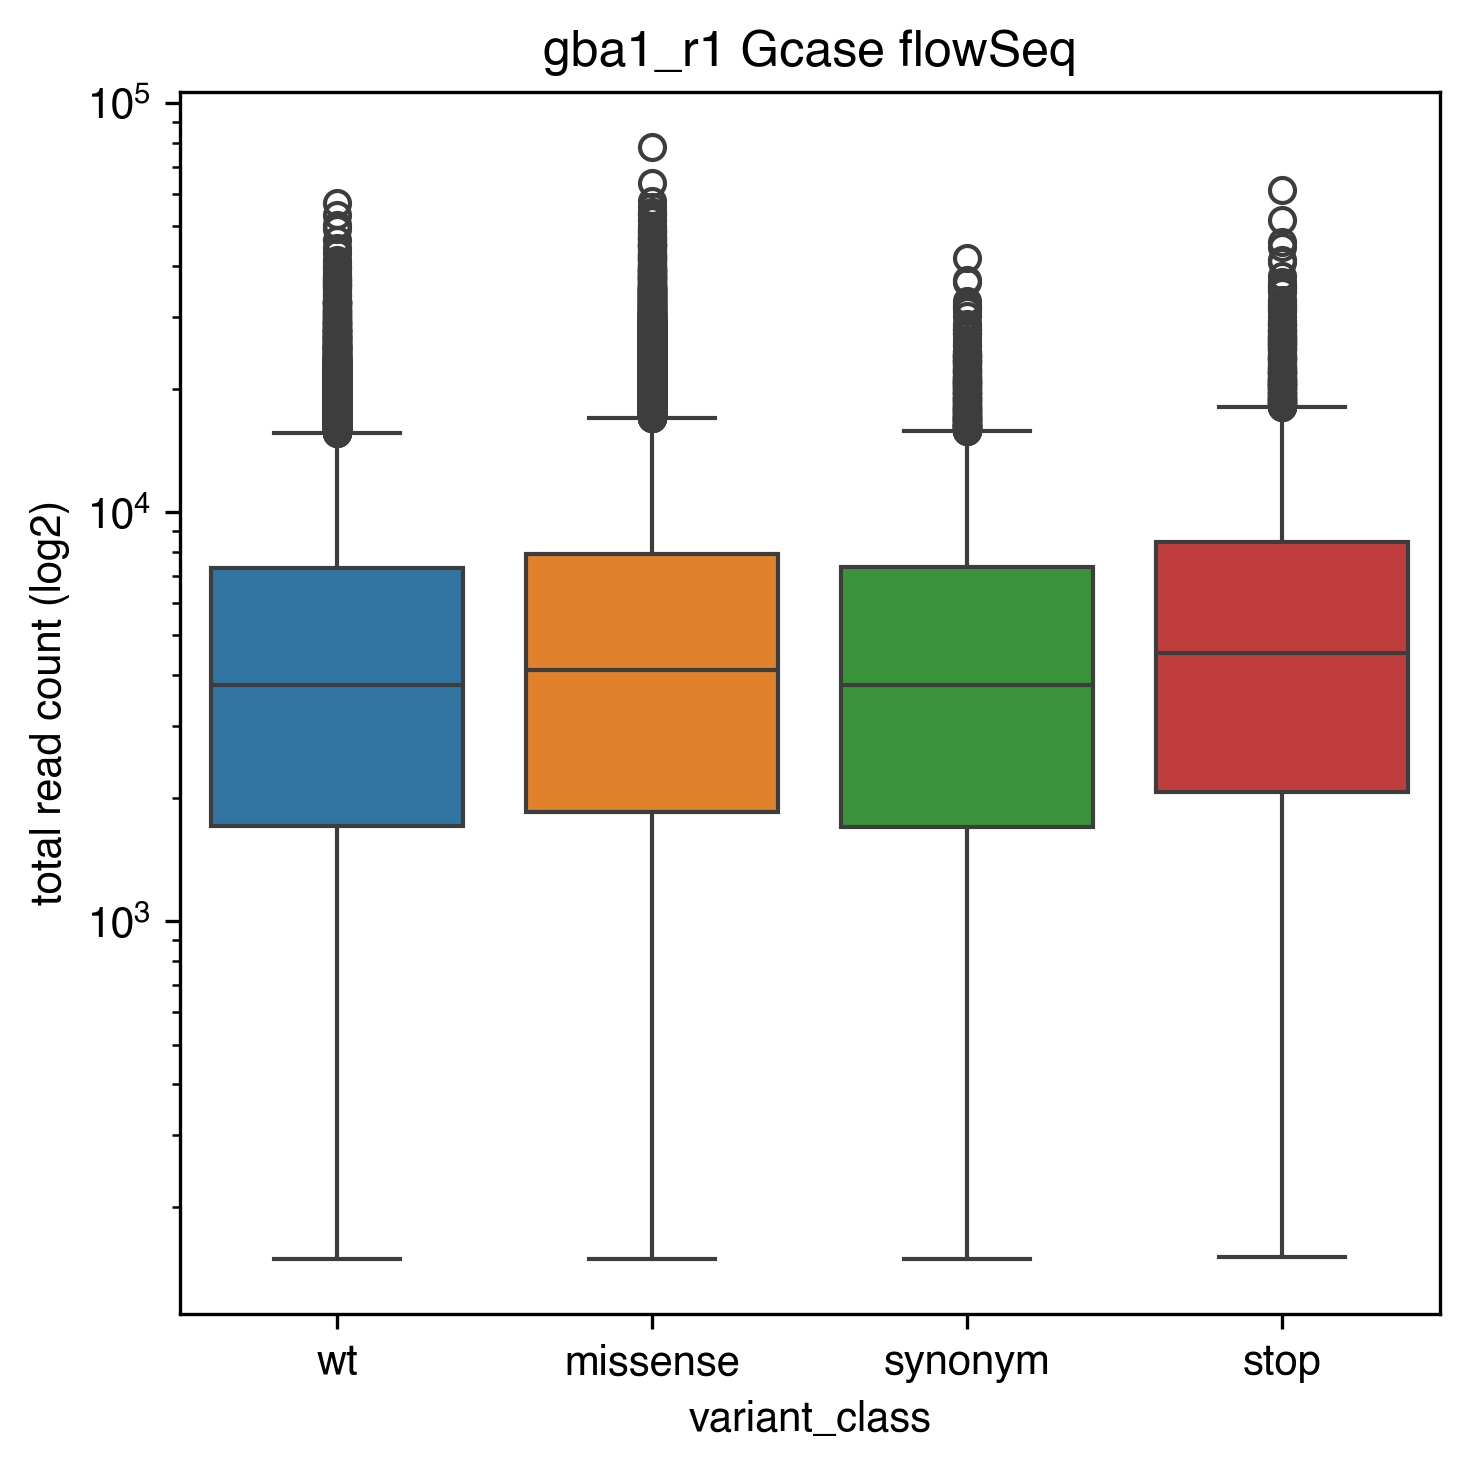

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up subplots
fig, axes = plt.subplots(nrows=1, ncols=len(barcode_scored), figsize=(5 * len(barcode_scored), 5))

# If only one subplot (i.e., len(barcode_scored) == 1), wrap axes in a list
if len(barcode_scored) == 1:
    axes = [axes]

# Plotting loop
for i, analysis in enumerate(barcode_scored.keys()):
    df = barcode_scored[analysis].copy()
    
    df['variant_class'] = df['variant_class'].str.replace('1 nonsynonymous', 'missense')
    df['variant_class'] = df['variant_class'].str.replace('wildtype', 'wt')
    df['variant_class'] = df['variant_class'].str.replace('synonymous', 'synonym')

    ax = axes[i]
    sns.boxplot(data=df, y='total_count', x='variant_class', hue='variant_class', ax=ax)
    ax.set_title(name_map[analysis].replace(' score ', " "))
    ax.set_ylabel('total read count (log2)')
    ax.set_yscale('log')

plt.tight_layout()
plt.savefig('results/figures/readcounts_for_variant_classes.pdf')

## save averaged barcode scores

In [10]:


df_bcScore=bc_score.copy()
df_bcScore['variant_class']=df_bcScore['aa_substitutions']

df_bcScore.loc[~df_bcScore['variant_class'].isin(['wildtype','synonymous']), 'variant_class'] = 'missense'

df_bcScore_data=df_bcScore.rename(columns=name_map)

df_bcScore_data.to_csv('results/scores/barcode_scores.csv', index=False)

In [127]:
df_bcScore_data[df_bcScore_data['aa_substitutions'] == 'M21*']

,barcode,aa_substitutions,codon_substitutions,gba1_r1 Gcase flowSeq,variant_class
8688,ATACATACGATCTCGGTATACCATATCATT,M21*,ATG21TAG,0.812745,missense
15807,GTTCCCGGCCGGATTAGTCTACATTTGCGT,M21*,ATG21TAG,0.583273,missense
17332,CACAACTCTCATAGCGGGGTATTAAACCGT,M21*,ATG21TAG,0.547612,missense
18266,CGTAAAGATGTGTCTGGCGCTCTCGGTAGT,M21*,ATG21TAG,0.576267,missense
24476,ACAAGGCATTCCCGGACGCGGACCACCGCT,M21*,ATG21TAG,0.456407,missense
32066,AAAGGAGGAGATCCGTCACAGGCGGTATAT,M21*,ATG21TAG,0.417367,missense
33852,CTGCCCCGTTGGACTGGAACTGATGTCGAT,M21*,ATG21TAG,0.400325,missense
37434,TTGCTGACATCGCAGCGGCCCGACTTTAAT,M21*,ATG21TAG,0.469371,missense
42882,CATCAGTATTGCGGAAGTTTCGCCTATGTG,M21*,ATG21TAG,0.540181,missense
46143,AGTAAAAGCTGCCTCCTATATATACGGCTG,M21*,ATG21TAG,0.455361,missense


In [11]:
# Calculating variant score withing each replicate
numeric_cols = bc_score.select_dtypes(include='number').columns

bc_score_grpd=bc_score.groupby('aa_substitutions')[numeric_cols].mean().reset_index()

# Select the rows corresponding to 'wildtype' and 'variants' separately
wildtype_score = bc_score_grpd[bc_score_grpd['aa_substitutions'] == 'wildtype']
variants_score = bc_score_grpd[~bc_score_grpd['aa_substitutions'].isin(['wildtype','synonymous'])]

# Drop 'aa_substitutions' column for division
wildtype_values = wildtype_score.drop(columns='aa_substitutions')
variants_values = variants_score.drop(columns='aa_substitutions')

# Perform division
variants_divided_by_wildtype = variants_values.divide(wildtype_values.iloc[0])

# Update 'variants_row' DataFrame with the result
variants_score.loc[:, variants_divided_by_wildtype.columns] = variants_divided_by_wildtype

variants_score['position']=variants_score['aa_substitutions'].apply(lambda x: int(x[1:-1]))
# calculating variant score for avregaes, here is the place to apply weighting
variants_score['gba1_r1']=np.log2(variants_score['gba1_r1'])



variants_score_dict={}
variants_score_dict['gba1_r1']=variants_score[['aa_substitutions','gba1_r1']]



variants_score.to_csv('results/scores/variants_scores.csv', index=False)

# Prepare barcode score for FDR calculations
make a df for each experiment, count number of barcodes they have in each replicates, and then rpeat the barcode scores based on their sum of barcode counts in the replicates

In [12]:
df=bc_score[['barcode','aa_substitutions','gba1_r1']]

df['Rep']=1
df.dropna(subset='gba1_r1', inplace=True)

gba1_r1_WtPool=list(df[df['aa_substitutions']=='wildtype']['gba1_r1'])
gba1_r1_VarRepBarCont=df.groupby('aa_substitutions').size().to_dict()
del gba1_r1_VarRepBarCont['wildtype']
del gba1_r1_VarRepBarCont['synonymous']

numeric_cols = df.select_dtypes(include='number').columns
gba1_r1_VarScore=df.groupby('aa_substitutions')[numeric_cols].mean()['gba1_r1'].to_dict()



## bootstap WT scores 10000 times for each experiment

lib_list=['gba1_r1_WtPool']

lib_list_dict={ 'gba1_r1':[gba1_r1_WtPool, gba1_r1_VarRepBarCont, gba1_r1_VarScore]}
                
                
start_time_clock = datetime.now().strftime("%H:%M:%S")
print("Start time:", start_time_clock)


wt_bootstraps={}
for j, library in enumerate(lib_list_dict.keys()):
    
    wt_pool=lib_list_dict[library][0] #list of wt barcode scores
                

    print ('wildtype bootstrapping for ' + library + ' please wait ...')

    print("current time:", datetime.now().strftime("%H:%M:%S")) 
    
    wt_bc_score_dists = {}

    for i in range (1, 300): #number of barcodes to sample from the pool
        wt_bc_score_avg_bootstrapped=[]
        
        for _ in range(10000): #bootstrapping size
            wt_bc_score_avg_bootstrapped.append(np.mean(random.sample(wt_pool, i)))
            
        wt_bc_score_dists[i]=wt_bc_score_avg_bootstrapped
    
    wt_bootstraps[lib_list[j]]=wt_bc_score_dists
    pd.DataFrame(wt_bc_score_dists).to_csv(f"results/bootstraps/{library}_wildtype_bootstraps.csv")
    
end_time_clock = datetime.now().strftime("%H:%M:%S")
print("Finish time:", end_time_clock)

## Calculate FDRvalues based on barcode scores and sum of their barcode counts in the replicates using wildtype bootstraps

#Read wildtype bootstrapping results 

wt_bootstraps_new={}
for library in lib_list_dict.keys():
                
    
    df = pd.read_csv(f'results/bootstraps/{library}_wildtype_bootstraps.csv', index_col=0,skiprows=1, names=np.arange(1,300))

    wt_bootstraps_new[library] = df.to_dict(orient='series')
###

def count_greater_smaller(number, lst):
    listMean=np.mean(lst)
    if number <= listMean:
        less_than_mean = [item for item in lst if item < listMean]
        fdr = sum(1 for item in less_than_mean if item < number)
        lst_size=len(less_than_mean)
        
    if number > listMean:
        more_than_mean = [item for item in lst if item > listMean]
        fdr = sum(1 for item in more_than_mean if item > number)
        lst_size=len(more_than_mean)
    if fdr == 0:
        fdr=1
    return (fdr/lst_size)

exclude_values = ['wildtype', 'stop', 'synonymous']


lib_list2=['wt_pool_a07a14_Sign']

for library in lib_list_dict.keys():
    
    FDRvalues = {}
    print (f'calculating FDR for {library}, please wait...')
    
    start_time_clock = datetime.now().strftime("%H:%M:%S")
    print("Start time:", start_time_clock)
    
    var_list = list(lib_list_dict[library][2].keys())
    var_list.remove('synonymous')
    var_list.remove('wildtype')
   
    WT_bootstraps=wt_bootstraps_new[library]

    for item in var_list:
        
 
        VarCount=lib_list_dict[library][1][item]
        
        VarScore=lib_list_dict[library][2][item]
        
        wt_bootstraps_list=list(WT_bootstraps[VarCount])
                                            
        fdr_1=count_greater_smaller(VarScore, wt_bootstraps_list)
                                             
        FDRvalues[item] = (fdr_1)
    
    print ("writing FDR values to df ...")
    _df = variants_score_dict[library]
    df2 = variants_score
    _df['FDRvalues']='' # this is to set FDRvalues empty 
    for item, value in FDRvalues.items():
        # Update the 'FDRvalues' column where 'aa_substitutions' matches the current item
        _df.loc[_df['aa_substitutions'] == item, 'FDRvalues'] = value
        df2.loc[df2['aa_substitutions'] == item, f'{library}_FDR'] = value
    
    _df.rename(columns={library: 'variant_score'}, inplace=True)
    
    _df=_df.dropna()
    variants_score_dict[library]=_df

    for library in lib_list_dict:
        variants_score_dict[library].to_csv(f"results/bootstraps/{library}_BArcodeScoresWithFDR.csv", index=False)

df2.to_csv('results/scores/variant_scores_withFDRs.csv')

end_time_clock = datetime.now().strftime("%H:%M:%S")
print("Finish time:", end_time_clock)    

# plot heatmaps
## first format dataframes, pivoting to dfs to have positions in rows and 20 amino acids list in columns

In [104]:
df

,barcode,aa_substitutions,gba1_r1,Rep
0,TAAGTCGCTGCGCGGATGTCGTTTTTTTTT,wildtype,0.644729,1
1,TTGTTTAGCTGTCAACCCCCCGTTTTTTTT,wildtype,0.675546,1
2,AACGTTCAGCACCTACAGGGATGTTTTTTT,A175R,0.659218,1
3,TCTATCGAACCGATGACAGACTTGTTTTTT,D63S,0.655001,1
4,AACCTGTAATGGTGTTTTGCATTGTTTTTT,S19F,0.744301,1
...,...,...,...,...
163637,AGGCGGAGTGATGGTAAAATCCGAAAAAAA,S84K,0.604353,1
163638,TGAGTTGGGATAGCGCTGTTCTCAAAAAAA,wildtype,0.807947,1
163639,GGGATAGATAGTAGAAGCACTTAAAAAAAA,wildtype,0.476397,1
163640,AGGGCTGGTTTTATTACGAGACAAAAAAAA,G103R,0.698222,1


In [13]:
def get_PosWTaaVARaa(aa_substitutions):
        pos = int(aa_substitutions[1:-1])
        wt_aa = aa_substitutions[:1]
        variant_aa = aa_substitutions[-1:]
        return wt_aa, pos, variant_aa

def pivot_df(df):

    df['wt_aa'], df['position'], df['variant_aa'] = zip(*df['aa_substitutions'].apply(get_PosWTaaVARaa))
    

    #pivot df for heatmapt plotting
    df_score=pd.pivot_table(df,
                   index='position', 
                   columns='variant_aa', 
                   values='variant_score').reset_index()

    df_score.sort_values('position', ascending=True, inplace=True)
    
    df_score = df_score.rename_axis(None, axis=1)
    df_score.reset_index(drop=True, inplace=True)


    #check if there is missing positions in df
    aa_range = range(1, 537)
    position_set = set(df_score.position)

    missing_elements = [item for item in aa_range if item not in position_set]
    if len(missing_elements) > 1:
        print("Missing positions from df:", missing_elements)
    

    if 'FDRvalues' in df.columns: #this will only work for average of replicates variant scores where they have FDR_values not for individual replicates
        df_se=pd.pivot_table(df,
                       index='position', 
                       columns='variant_aa', 
                       values='FDRvalues').reset_index()

        df_se.sort_values('position', ascending=True, inplace=True)


        #check if there is missing positions in df
        position_set = set(df_se.position)

        missing_elements = [item for item in aa_range if item not in position_set]
        if len(missing_elements) > 1:
            print("Missing positions from df:", missing_elements)
        
    df_score['median_score']=df_score[AA_LIST].median(axis=1)
    df_score['mean_score']=df_score[AA_LIST].mean(axis=1)
    return df_score


## pivot average variant scores and store in variantsScore_melt dictionary

In [14]:
geneseq='atggagttttcaagtccttccagagaggaatgtcccaagcctttgagtagggtaagcatcatggctggcagcctcacaggattgcttctacttcaggcagtgtcgtgggcatcaggtgcccgcccctgcatccctaaaagcttcggctacagctcggtggtgtgtgtctgcaatgccacatactgtgactcctttgaccccccgacctttcctgcccttggtaccttcagccgctatgagagtacacgcagtgggcgacggatggagctgagtatggggcccatccaggctaatcacacgggcacaggcctgctactgaccctgcagccagaacagaagttccagaaagtgaagggatttggaggggccatgacagatgctgctgctctcaacatccttgccctgtcaccccctgcccaaaatttgctacttaaatcgtacttctctgaagaaggaatcggatataacatcatccgggtacccatggccagctgtgacttctccatccgcacctacacctatgcagacacccctgatgatttccagttgcacaacttcagcctcccagaggaagataccaagctcaagatacccctgattcaccgagccctgcagttggcccagcgtcccgtttcactccttgccagcccctggacatcacccacttggctcaagaccaatggagcggtgaatgggaaggggtcactcaagggacagcccggagacatctaccaccagacctgggccagatactttgtgaagttcctggatgcctatgctgagcacaagttacagttctgggcagtgacagctgaaaatgagccttctgctgggctgttgagtggataccccttccagtgcctgggcttcacccctgaacatcagcgagacttcattgcccgtgacctaggtcctaccctcgccaacagtactcaccacaatgtccgcctactcatgctggatgaccaacgcttgctgctgccccactgggcaaaggtggtactgacagacccagaagcagctaaatatgttcatggcattgctgtacattggtacctggactttctggctccagccaaagccaccctaggggagacacaccgcctgttccccaacaccatgctctttgcctcagaggcctgtgtgggctccaagttctgggagcagagtgtgcggctaggctcctgggatcgagggatgcagtacagccacagcatcatcacgaacctcctgtaccatgtggtcggctggaccgactggaaccttgccctgaaccccgaaggaggacccaattgggtgcgtaactttgtcgacagtcccatcattgtagacatcaccaaggacacgttttacaaacagcccatgttctaccaccttggccacttcagcaagttcattcctgagggctcccagagagtggggctggttgccagtcagaagaacgacctggacgcagtggcactgatgcatcccgatggctctgctgttgtggtcgtgctaaaccgctcctctaaggatgtgcctcttaccatcaaggatcctgctgtgggcttcctggagacaatctcacctggctactccattcacacctacctgtggcgtcgccagtga'
aa_seq = Seq(geneseq).translate()
aa_seq

AA_LIST=sfmap_normal.AA_LIST

variantsScore_melt={}
for library in variants_score_dict.keys(): 
    
    df_singles=variants_score_dict[library]
    
    df_singles=df_singles[~df_singles['aa_substitutions'].isin(['synonymous','wildtype'])].reset_index(drop=True)
    df_singles.rename(columns={'gba1_r1': 'variant_score'}, inplace=True)
    
    df_melt=pivot_df(df_singles)
    
    
    variantsScore_melt[library]=df_melt
    variants_score_dict[library]=df_singles

    df_melt['wt_aa'] = df_melt['position'].apply(lambda x: aa_seq[x - 1] if pd.notnull(x) and x > 0 else None)

    df_melt.to_csv('gba1_app/data/variants_scores_melt.csv', index=False)
    df_melt.to_csv('data/variants_scores_melt.csv', index=False)

## plot heatmaps, select average or single replicates

In [105]:
df_score


,position,*,A,C,D,E,F,G,H,I,...,Q,R,S,T,V,W,Y,median_score,mean_score,wt_aa
0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.048033,NaN,NaN,NaN,NaN,NaN,0.048033,0.048033,M
1,2,-0.300357,-0.147217,-0.170653,-0.090010,0.000000,-0.042320,0.003438,-0.064462,0.009566,...,-0.108444,-0.001447,0.123775,0.218025,-0.064955,0.014059,-0.152615,-0.049346,-0.042157,E
2,3,-0.075575,-0.048884,0.089094,0.007931,-0.092191,0.000000,-0.079384,0.031295,-0.195201,...,-0.014868,0.052631,0.040988,-0.067444,0.045762,0.044754,0.150337,0.005987,-0.003882,F
3,4,-0.172924,0.000705,-0.069888,0.041292,0.062782,-0.088097,-0.011604,0.042806,0.044000,...,-0.040131,-0.028730,0.000000,-0.066947,-0.010886,-0.080759,0.027226,-0.020167,-0.018473,S
4,5,-0.112231,0.065457,0.046913,-0.153231,-0.014692,0.031961,0.043117,0.052493,0.161164,...,-0.117195,-0.023721,0.000000,-0.015778,0.042576,-0.001582,-0.191576,0.006099,-0.006441,S
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
532,533,-0.469495,-0.355960,-0.328183,-0.585729,-0.528144,0.154113,-0.495197,-0.376471,-0.103085,...,-0.374204,-0.429721,-0.424117,-0.509399,-0.208019,0.000000,-0.021413,-0.400294,-0.360484,W
533,534,-0.433093,0.266581,0.210565,-0.082425,-0.187229,-0.088365,-0.094111,-0.027619,-0.035031,...,0.044720,0.000000,0.123370,-0.060462,-0.029462,-0.120358,-0.281871,-0.031346,-0.031448,R
534,535,-0.259746,-0.101226,-0.231762,-0.472911,-0.233057,-0.307969,-0.222338,0.003044,0.158441,...,0.287153,0.000000,-0.354563,-0.141154,-0.144460,-0.367988,-0.088673,-0.183399,-0.161287,R
535,536,0.108058,0.028286,-0.009894,-0.115236,0.155713,-0.172241,-0.112416,-0.143662,0.170711,...,0.000000,-0.035925,0.004662,0.081090,-0.049364,0.047324,0.084898,0.016474,0.000692,Q


In [15]:
for library in variantsScore_melt.keys():
    
    #if library[-3:] == 'avg': continue #turn this on if you want only plot replictes
    #if library[-3:] != 'avg': continue #turn this on if you want only plot averages
    
    df_score=variantsScore_melt[library]
    
    for i, j in enumerate(aa_seq):
        df_score.at[i, j] = 0
    
    
    pdf = PdfPages(f'results/figures/heatmaps/{library}_heatmap.pdf')

    df_score.reset_index(drop=True, inplace=True)


    vmin = -0.8
    vmax = 0.5
    
   
       
    
    print (f'plotting heatmap for {library}, wait...')
    # Call the sfmap_plot function
    sfmap_normal.sfmap_plot(df_score[AA_LIST], pdf, "scores", aa_seq, (160,6),
            #df_se=df_se[AA_LIST],
            sfmap_name= name_map[library] ,
            show_colorbar=True,
            show_positions=True,
            show_variants=True,
            show_wt=True,
            aa_list=AA_LIST,
            aa_label_groups=[],
            vmin=vmin,
            vmax=vmax        )
    # Close the pdf object
    pdf.close()

    print ('done!')

plotting heatmap for gba1_r1, wait...
done!


In [16]:
!pip install dash

In [ ]:
# Copyright (c) 2025 Vahid Aslanzadeh
# All rights reserved.
#
# This software is proprietary and confidential. No part of this code
# may be copied, modified, distributed, or used in any form without
# explicit written permission from the author.
#
# Author: Vahid Aslanzadeh
# Contact: vaslanzadeh@gmail.com

import os
import dash
import pandas as pd
import plotly.graph_objects as go
from dash import Input, Output, State, dcc, html
from plotly.colors import get_colorscale
from scipy.stats import gaussian_kde


# ========= Load CSVs ===========
data_directory = "data/"
data_files = {
    file: pd.read_csv(os.path.join(data_directory, file))
    for file in os.listdir(data_directory)
    if file.endswith(".csv")
}

# ========= Function to center zero (white) ===========
def generate_centered_colorscale(zmin, zmax, base_colorscale='RdBu_r'):
    colors = get_colorscale(base_colorscale)
    zero_position = (0 - zmin) / (zmax - zmin)

    new_colorscale = []
    for loc, color in colors:
        if loc <= 0.5:
            new_loc = loc * zero_position / 0.5
        else:
            new_loc = zero_position + ((loc - 0.5) * (1 - zero_position) / 0.5)
        new_colorscale.append([new_loc, color])
    return new_colorscale

# ========= App Setup ===========
app = dash.Dash(__name__)
app.title = "Heatmap Viewer"

# ========= Layout ===========
app.layout = html.Div([
    html.H1("Variant effects score distribution and heatmap"),

    html.Label("Select a variant effect score dataset (csv format):"),
    dcc.Dropdown(
        id="file-dropdown",
        options=[{"label": file, "value": file} for file in data_files.keys()],
        multi=False
    ),

    html.Div([
        html.Label("Min (zmin):"),
        dcc.Input(id='zmin-input', type='number', value=-0.8, step=0.1),

        html.Label("Max (zmax):", style={'marginLeft': '20px'}),
        dcc.Input(id='zmax-input', type='number', value=0.5, step=0.1),
    ], style={'marginTop': '10px', 'marginBottom': '20px'}),

    html.Br(),

    html.Label("Search mutations  (e.g., C165Y, D166P):"),
    dcc.Input(id='mutation-input', type='text', debounce=True, style={'width': '150px'}),
    html.Div(id='mutation-output', style={'marginTop': '10px', 'fontWeight': 'bold'}),

    html.Br(),
    dcc.Graph(id="score-distribution"),
    dcc.Graph(id="heatmap"),

    # 👇 Footer added here
    html.Div(
        "© Vahid Aslanzadeh – All rights reserved",
        style={
            "textAlign": "center",
            "marginTop": "50px",
            "marginBottom": "20px",
            "fontSize": "12px",
            "color": "#888"
        }
    )
])

# ========= Heatmap Callback ===========
@app.callback(
    Output("heatmap", "figure"),
    Input("file-dropdown", "value"),
    Input("zmin-input", "value"),
    Input("zmax-input", "value")
)
def update_heatmap(file, zmin, zmax):
    # Guard clause for missing input
    if file is None or zmin is None or zmax is None:
        return go.Figure()

    # Make sure values are float
    try:
        zmin = float(zmin)
        zmax = float(zmax)
    except (TypeError, ValueError):
        return go.Figure()

    df = data_files[file]
    z_data = df.loc[:, "*":"Y"].values.T
    x_data = df["position"]
    y_labels = df.loc[:, "*":"Y"].columns

    hover_text = [
        [
            f"Mutation: {wt}{pos}{variant}<br>Mutation Score: {score:.2f}<br>Median Score: {median:.2f}"
            for pos, score, wt, median in zip(
                x_data,
                row,
                df["wt_aa"],
                df["median_score"]
            )
        ]
        for variant, row in zip(y_labels, z_data)
    ]

    colorscale = generate_centered_colorscale(zmin, zmax)

    heatmap_fig = go.Figure(data=go.Heatmap(
        z=z_data,
        x=x_data,
        y=y_labels,
        colorscale=colorscale,
        zmin=zmin,
        zmax=zmax,
        colorbar=dict(
            title=dict(
                text="variant score (log2)",
                side="right",
                font=dict(size=12)
            ),
            tickvals=[zmin, 0, zmax]
        ),
        hoverongaps=False,
        text=hover_text,
        hovertemplate="%{text}"
    ))

    heatmap_fig.update_layout(
        title=file,
        xaxis=dict(title="Position", showgrid=False),
        yaxis=dict(
            tickmode="array",
            tickvals=list(range(len(y_labels))),
            ticktext=y_labels,
            automargin=True,
            fixedrange=True,
            showgrid=False
        ),
        plot_bgcolor="grey",
    )

    return heatmap_fig
# ========= Mutation Lookup Callback ===========
@app.callback(
    Output("mutation-output", "children"),
    Input("mutation-input", "value"),
    State("file-dropdown", "value")
)
def lookup_mutation(mutation_str, file):
    if not mutation_str or file is None:
        return ""

    df = data_files[file]
    results = []

    try:
        mutations = [m.strip().upper() for m in mutation_str.split(",") if m.strip()]
        for m in mutations:
            if len(m) < 3:
                results.append(f"Invalid format: '{m}'")
                continue

            wt = m[0]
            variant = m[-1]
            try:
                pos = int(m[1:-1])
            except ValueError:
                results.append(f"Invalid position in: '{m}'")
                continue

            match = df[df["position"] == pos]

            if match.empty:
                results.append(f"{m}: Position {pos} not found.")
                continue

            row = match.iloc[0]
            actual_wt = row["wt_aa"]
            if wt != actual_wt:
                results.append(f"{m}: WT amino acid mismatch, expected {actual_wt}")
                continue

            if variant not in df.columns:
                results.append(f"{m}: Variant {variant} not found.")
                continue

            score = row[variant]
            median = row["median_score"]
            results.append(f"{m} → Variant Score: {score:.2f}, Median Score: {median:.2f}")

        return html.Ul([html.Li(r) for r in results])

    except Exception as e:
        return f"Error: {str(e)}"
@app.callback(
    Output("score-distribution", "figure"),
    Input("file-dropdown", "value"),
    Input("mutation-input", "value")
)
def update_distribution(file, mutation_str):
    if not file:
        return go.Figure()

    df = data_files[file]

    # Collect all variant scores and stop codon scores separately
    variant_cols = df.loc[:, "*":"Y"].columns
    all_scores = df[variant_cols].values.flatten()
    stop_scores = df["*"].values.flatten()

    # Clean: Remove NaNs
    all_scores = all_scores[~pd.isnull(all_scores)]
    stop_scores = stop_scores[~pd.isnull(stop_scores)]

    # Prepare figure
    fig = go.Figure()

    # Add histogram of all scores
    fig.add_trace(go.Histogram(
        x=all_scores,
        nbinsx=100,
        name='All Variant Scores',
        marker=dict(color='lightblue'),
        opacity=0.75
    ))

    # Add histogram of stop codon scores (overlaid)
    fig.add_trace(go.Histogram(
        x=stop_scores,
        nbinsx=100,
        name='Stop Codon Scores',
        marker=dict(color='red'),
        opacity=0.5
    ))

    # Overlay lines for mutation(s)
    if mutation_str:
        mutations = [m.strip().upper() for m in mutation_str.split(",") if m.strip()]
        for m in mutations:
            if len(m) < 3:
                continue

            wt = m[0]
            variant = m[-1]
            try:
                pos = int(m[1:-1])
            except:
                continue

            match = df[df["position"] == pos]
            if match.empty:
                continue

            row = match.iloc[0]
            if wt != row["wt_aa"] or variant not in df.columns:
                continue

            score = row[variant]
            fig.add_vline(
                x=score,
                line=dict(color="green", width=2, dash="dash"),
                annotation_text=m,
                annotation_position="top right"
            )

    # Update layout with x-axis tick settings
    fig.update_layout(
        title="Distribution of Variant Scores (Red = Stop Codons)",
        xaxis_title="Variant Score",
        yaxis_title="Count",
        bargap=0.05,
        showlegend=True,
        legend=dict(
            orientation="h",
            yanchor="bottom",
            y=1.02,
            xanchor="right",
            x=1
        ),
        height=300,
        xaxis=dict(
            tickmode='linear',
            tick0=-1.0,  # Starting point (adjust based on your data range)
            dtick=0.1,   # Interval between ticks
            showgrid=True,
            gridwidth=1,
            gridcolor='LightGrey'
        )
    )
    
    # Add vertical line at 0 in black
    fig.add_vline(
        x=0, 
        line_width=1, 
        line_color="black"
    )

    return fig
# ========= Run ===========
if __name__ == "__main__":
    app.run(debug=True, port=int(os.getenv("PORT", 8051)), host="0.0.0.0")

In [122]:
# Copyright (c) 2025 Vahid Aslanzadeh
# All rights reserved.
#
# This software is proprietary and confidential. No part of this code
# may be copied, modified, distributed, or used in any form without
# explicit written permission from the author.
#
# Author: Vahid Aslanzadeh
# Contact: vaslanzadeh@gmail.com

import os
import dash
import pandas as pd
import plotly.graph_objects as go
from dash import Input, Output, State, dcc, html
from plotly.colors import get_colorscale


# ========= Load CSVs ===========
data_directory = "data/"
data_files = {
    file: pd.read_csv(os.path.join(data_directory, file))
    for file in os.listdir(data_directory)
    if file.endswith(".csv")
}

# ========= Function to center zero (white) ===========
def generate_centered_colorscale(zmin, zmax, base_colorscale='RdBu_r'):
    colors = get_colorscale(base_colorscale)
    zero_position = (0 - zmin) / (zmax - zmin)

    new_colorscale = []
    for loc, color in colors:
        if loc <= 0.5:
            new_loc = loc * zero_position / 0.5
        else:
            new_loc = zero_position + ((loc - 0.5) * (1 - zero_position) / 0.5)
        new_colorscale.append([new_loc, color])
    return new_colorscale

# ========= App Setup ===========
app = dash.Dash(__name__)
app.title = "VEMViewer"

# ========= Layout ===========
app.layout = html.Div([
    html.H1("Variant effects score distribution and heatmap"),

    html.Label("Select a variant effect score dataset (csv format):"),
    dcc.Dropdown(
        id="file-dropdown",
        options=[{"label": file, "value": file} for file in data_files.keys()],
        multi=False
    ),

    html.Br(),
    
    # Search mutations section (kept before distribution plot)
    html.Label("Search mutations (e.g., C165Y, D166P):"),
    dcc.Input(id='mutation-input', type='text', debounce=True, style={'width': '150px'}),
    html.Div(id='mutation-output', style={'marginTop': '10px', 'fontWeight': 'bold'}),

    html.Br(),
    dcc.Graph(id="score-distribution"),
    
    # Min/Max controls moved after distribution plot
    html.Div([
        html.Div("Heatmap Colorbar Range", style={'marginBottom': '10px', 'fontWeight': 'normal'}),
        html.Div([
            html.Label("Min Score:", style={'marginRight': '10px'}),
            dcc.Input(id='zmin-input', type='number', value=-0.8, step=0.1, style={'marginRight': '20px'}),

            html.Label("Max Score:", style={'marginRight': '10px'}),
            dcc.Input(id='zmax-input', type='number', value=0.5, step=0.1),
        ], style={'marginTop': '10px', 'marginBottom': '20px'}),
    ]),

    dcc.Graph(id="heatmap"),

    # Footer
    html.Div(
        "© Vahid Aslanzadeh – All rights reserved",
        style={
            "textAlign": "center",
            "marginTop": "50px",
            "marginBottom": "20px",
            "fontSize": "12px",
            "color": "#888"
        }
    )
])
# ========= Heatmap Callback ===========
@app.callback(
    Output("heatmap", "figure"),
    Input("file-dropdown", "value"),
    Input("zmin-input", "value"),
    Input("zmax-input", "value")
)
def update_heatmap(file, zmin, zmax):
    # Guard clause for missing input
    if file is None or zmin is None or zmax is None:
        return go.Figure()

    # Make sure values are float
    try:
        zmin = float(zmin)
        zmax = float(zmax)
    except (TypeError, ValueError):
        return go.Figure()

    df = data_files[file]
    z_data = df.loc[:, "*":"Y"].values.T
    x_data = df["position"]
    y_labels = df.loc[:, "*":"Y"].columns

    hover_text = [
        [
            f"Mutation: {wt}{pos}{variant}<br>Mutation Score: {score:.2f}<br>Median Score: {median:.2f}"
            for pos, score, wt, median in zip(
                x_data,
                row,
                df["wt_aa"],
                df["median_score"]
            )
        ]
        for variant, row in zip(y_labels, z_data)
    ]

    colorscale = generate_centered_colorscale(zmin, zmax)

    heatmap_fig = go.Figure(data=go.Heatmap(
        z=z_data,
        x=x_data,
        y=y_labels,
        colorscale=colorscale,
        zmin=zmin,
        zmax=zmax,
        colorbar=dict(
            title=dict(
                text="variant score (log2)",
                side="right",
                font=dict(size=12)
            ),
            tickvals=[zmin, 0, zmax]
        ),
        hoverongaps=False,
        text=hover_text,
        hovertemplate="%{text}"
    ))

    heatmap_fig.update_layout(
        title=file,
        xaxis=dict(title="Position", showgrid=False),
        yaxis=dict(
            tickmode="array",
            tickvals=list(range(len(y_labels))),
            ticktext=y_labels,
            automargin=True,
            fixedrange=True,
            showgrid=False
        ),
        plot_bgcolor="grey",
    )

    return heatmap_fig
# ========= Mutation Lookup Callback ===========
@app.callback(
    Output("mutation-output", "children"),
    Input("mutation-input", "value"),
    State("file-dropdown", "value")
)
def lookup_mutation(mutation_str, file):
    if not mutation_str or file is None:
        return ""

    df = data_files[file]
    results = []

    try:
        mutations = [m.strip().upper() for m in mutation_str.split(",") if m.strip()]
        for m in mutations:
            if len(m) < 3:
                results.append(f"Invalid format: '{m}'")
                continue

            wt = m[0]
            variant = m[-1]
            try:
                pos = int(m[1:-1])
            except ValueError:
                results.append(f"Invalid position in: '{m}'")
                continue

            match = df[df["position"] == pos]

            if match.empty:
                results.append(f"{m}: Position {pos} not found.")
                continue

            row = match.iloc[0]
            actual_wt = row["wt_aa"]
            if wt != actual_wt:
                results.append(f"{m}: WT amino acid mismatch, expected {actual_wt}")
                continue

            if variant not in df.columns:
                results.append(f"{m}: Variant {variant} not found.")
                continue

            score = row[variant]
            median = row["median_score"]
            results.append(f"{m} → Variant Score: {score:.2f}, Position {m[:-1]} Median Score: {median:.2f}")

        return html.Ul([html.Li(r) for r in results])

    except Exception as e:
        return f"Error: {str(e)}"
@app.callback(
    Output("score-distribution", "figure"),
    Input("file-dropdown", "value"),
    Input("mutation-input", "value")
)
def update_distribution(file, mutation_str):
    if not file:
        return go.Figure()

    df = data_files[file]

    # Collect all variant scores and stop codon scores separately
    variant_cols = df.loc[:, "*":"Y"].columns
    all_scores = df[variant_cols].values.flatten()
    stop_scores = df["*"].values.flatten()

    # Clean: Remove NaNs
    all_scores = all_scores[~pd.isnull(all_scores)]
    stop_scores = stop_scores[~pd.isnull(stop_scores)]

    # Prepare figure
    fig = go.Figure()

    # Add histogram of all scores
    fig.add_trace(go.Histogram(
        x=all_scores,
        nbinsx=100,
        name='All Variant Scores',
        marker=dict(color='lightblue'),
        opacity=0.75
    ))

    # Add histogram of stop codon scores (overlaid)
    fig.add_trace(go.Histogram(
        x=stop_scores,
        nbinsx=100,
        name='Stop Codon Scores',
        marker=dict(color='red'),
        opacity=0.5
    ))

    # Overlay lines for mutation(s)
    if mutation_str:
        mutations = [m.strip().upper() for m in mutation_str.split(",") if m.strip()]
        for m in mutations:
            if len(m) < 3:
                continue

            wt = m[0]
            variant = m[-1]
            try:
                pos = int(m[1:-1])
            except:
                continue

            match = df[df["position"] == pos]
            if match.empty:
                continue

            row = match.iloc[0]
            if wt != row["wt_aa"] or variant not in df.columns:
                continue

            score = row[variant]
            fig.add_vline(
                x=score,
                line=dict(color="green", width=2, dash="dash"),
                annotation_text=m,
                annotation_position="top right"
            )

    # Update layout with x-axis tick settings
    fig.update_layout(
        title="Distribution of Variant Scores (Red = Stop Codons)",
        xaxis_title="Variant Score",
        yaxis_title="Count",
        bargap=0.05,
        showlegend=True,
        legend=dict(
            orientation="h",
            yanchor="bottom",
            y=1.02,
            xanchor="right",
            x=1
        ),
        height=300,
        xaxis=dict(
            tickmode='linear',
            tick0=-1.0,  # Starting point (adjust based on your data range)
            dtick=0.1,   # Interval between ticks
            showgrid=True,
            gridwidth=1,
            gridcolor='LightGrey'
        ),
        plot_bgcolor='white',  # Set plot background to white
        paper_bgcolor='white', # Set surrounding area background to white
        
    )
    
    # Add vertical line at 0 in black
    fig.add_vline(
        x=0, 
        line_width=1, 
        line_color="black"
    )

    return fig
# ========= Run ===========
if __name__ == "__main__":
    app.run(debug=True, port=int(os.getenv("PORT", 8051)), host="0.0.0.0")

In [121]:
'C165T'[:-1]

'C165'